# 1.3 — Pirkimo dalies aktualumas: „TensorFlow / Keras“ neuroninis tinklas

**Pritaikyta iš kurso užrašinio** [AdventureWorks DW using TensorFlow](https://colab.research.google.com/drive/1LLFM2Ba5jAZSna8JnS44frwSLW9mx5As?usp=sharing).

**Ką daro originalas.** „AdventureWorks“ klientų lentelėje `BikeBuyer` yra `y` (ar klientas pirko dviratį), o kiti stulpeliai — `X`. Kodas pašalina identifikatorius, padalija duomenis į mokymo / validavimo / testavimo dalis, normalizuoja skaitinius ir užkoduoja kategorinius požymius, sujungia juos ir moko kelis `Dense` sluoksnius dvejetainei klasifikacijai, tada vertina, išsaugo ir iš naujo įkelia modelį.

**Kas pakeista.** Vietoje kliento pirkėjo — **viešojo pirkimo dalis**, o `y` — ar ją verta perduoti kliento peržiūrai. Dvejetainė klasifikacija ir `Dense` tinklas išlieka. Pridėta: padalijimas **pagal pirkimo ID** (kad to paties pirkimo dalys nepatektų į mokymą ir testą), klasių svoriai (aktualių dalių mažuma), paprasta bazinė taisyklė palyginimui ir praleistų aktualių dalių analizė.

Šis modelis yra **laboratorinis klasifikatorius**, ne viso produkto tinkamumo įrodymas. Lygiai tie patys duomenys ir padalijimas naudojami sprendimų miško užrašinyje.


## Duomenys: kas yra `X` ir `y`

**Viena eilutė = viena viešojo pirkimo dalis.** Šaltinis: Europos Sąjungos oficialus [TED API](https://docs.ted.europa.eu/api/latest/index.html) (Lietuvos perkančiųjų organizacijų skelbimai apie pirkimą, eForms XML). Kiekvienai daliai išsaugoti pirkimo ID, dalies numeris, TED nuoroda ir atsisiuntimo laikas — faile `private/1_3_zymos.csv`.

- **`y`** — ar dalį verta perduoti molekulinės biologijos reagentų ir laboratorinių reikmenų tiekėjo peržiūrai (`1`) ar ne (`0`).
  **Svarbu:** šias žymas uždėjo **AI agentas** pagal privačius kliento katalogus ir rašytines taisykles (`labeler = claude_agentas`), o 42 iš pradžių neaiškios dalys priskirtos pagal spėjimą. Tai **ne žmogaus patvirtintas aukso standartas**. Todėl žemiau esantys rezultatai rodo, kaip gerai modeliai atkartoja šias žymas, o ne tikrą kliento sprendimą.
- **`X`** — tik tai, kas žinoma iš skelbimo prieš sprendimą:
  1. tekstas: dalies pavadinimas, perkamų objektų aprašymas ir pirkimo pavadinimas;
  2. BVPŽ (CPV) kodų požymiai;
  3. požymiai, apskaičiuoti lyginant su **dabartiniu kliento katalogu**: kiek dalies žodžių yra katalogo produktų pavadinimų žodyne (`private/1_3_katalogo_zodynas.json`, sudarytas tik iš pavadinimų, be kainų) ir kiek pataikoma į katalogo kategorijų raktinius žodžius.

**Nenaudojama kaip `X`:** agento užuominų stulpeliai, žymos priežastis, atrankos grupė (ji rodo, kaip pirkimas buvo surinktas, todėl nutekintų atsakymą) ir perkančioji organizacija.

**Ribos:** TED turi tik viršslenkstinius pirkimus; techninės specifikacijos dažnai yra CVP prieduose, todėl dalies aprašymas gali būti trumpas. Lentelėje nėra katalogo eilučių ar kainų.


## 1. Aplinka ir privatūs failai

Užrašinis vykdomas lokaliai (arba „Colab“ su įkeltu `private/` aplanku). Privatūs failai į viešą saugyklą nekeliami.


In [1]:
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRIVATE = Path(os.getenv("TENDER_FIT_PRIVATE_DIR", PROJECT / "private"))
LABELS_CSV = PRIVATE / "1_3_zymos.csv"
VOCAB_JSON = PRIVATE / "1_3_katalogo_zodynas.json"
assert LABELS_CSV.exists(), f"Nerastas {LABELS_CSV}. Nurodykite TENDER_FIT_PRIVATE_DIR."
assert VOCAB_JSON.exists(), f"Nerastas {VOCAB_JSON}. Paleiskite scripts/build_catalog_vocab.py."

import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__)


TensorFlow 2.19.0


## 2. Įkelti pažymėtas dalis


In [2]:
raw = pd.read_csv(LABELS_CSV, dtype=str, encoding="utf-8-sig").fillna("")
raw = raw[raw["label"].isin(["0", "1"])].copy()
raw["y"] = raw["label"].astype(int)
raw["text"] = (raw["lot_title"] + " . " + raw["items_text"] + " . " + raw["procurement_title"]).str.lower()
print("Dalių:", len(raw), "| pirkimų:", raw.procurement_id.nunique())
print("Žymos:", raw.y.value_counts().to_dict())
print("Pirkimų su bent viena aktualia dalimi:", raw.loc[raw.y == 1, "procurement_id"].nunique())
print("Žymėtojai:", raw.labeler.value_counts().to_dict())


Dalių: 380 | pirkimų: 122
Žymos: {0: 311, 1: 69}
Pirkimų su bent viena aktualia dalimi: 24
Žymėtojai: {'claude_agentas': 380}


## 3. Požymiai `X`

`build_features` kiekvienai daliai suskaičiuoja: kiek žodžių yra kliento katalogo žodyne, kiek pataikoma į teigiamų (katalogo kategorijų) ir neigiamų (klinika, vaistai, medicinos priemonės, chemija, įranga) raktinių žodžių grupes, ir BVPŽ kodų prefiksus. Tai tie patys požymiai abiem modeliams.


In [3]:
catalog_vocab = set(json.loads(VOCAB_JSON.read_text(encoding="utf-8"))["token_doc_freq"])
TOKEN = re.compile(r"[a-ząčęėįšųūž][a-ząčęėįšųūž0-9\-]{2,}")

# Katalogo kategorijų raktiniai žodžiai (LT kamienai + EN). Sudaryti pagal katalogų kategorijas,
# ne pagal konkrečius pirkimus.
POSITIVE_GROUPS = {
    "kw_antikunai": ["antikūn", "antibod", "imunoglobulin"],
    "kw_elisa": ["elisa", "imunofermentin", "imunoanaliz"],
    "kw_pcr": ["pcr", "pgr", "polimeraz", "polymeras", "amplifik", "taq", "master mix", "atvirkštin"],
    "kw_fermentai": ["ferment", "enzym", "restrikc", "ligaz", "nukleaz"],
    "kw_nukleino": ["oligonukleot", "pradmen", "primer", "zond", "sirna", "sgrna", "dnr", "rnr", "nukleotid", "dntp", "dna", "rna"],
    "kw_sekoskaita": ["sekoskait", "sequenc", "bibliotek", "ngs"],
    "kw_baltymai": ["rekombinant", "baltym", "citokin", "protein", "peptid", "ląstelių linij"],
    "kw_terpes": ["terp", "medium", "agar", "mielių", "bakterijų augin"],
    "kw_plastikas": ["mėgintuvėl", "plokštel", "antgal", "pipeči", "pipet", "juostel", "krioviel"],
    "kw_reagentai": ["reagent", "molekulin", "genetin", "genomin"],
}
NEGATIVE_GROUPS = {
    "kw_klinika": ["analizator", "klinikin", "šlapim", "kraujo", "hematolog", "koaguliac", "diagnostin"],
    "kw_vaistai": ["vaist", "tablet", "injekc", "infuz", "vakcin"],
    "kw_med_priemones": ["švirkšt", "adat", "pirštin", "tvarst", "chirurg", "kateter", "kaukė"],
    "kw_chemija": ["rūgšt", "tirpikl", "etanol", "acetonitril", "druska", "chemin"],
    "kw_paslaugos": ["paslaug", "aptarnav", "remont", "priežiūr", "nuom"],
    "kw_iranga": ["įrang", "prietais", "aparat", "centrifug", "mikroskop", "spektrofotometr"],
}
CPV_PREFIXES = {"cpv_336965": "336965", "cpv_33696": "33696", "cpv_38437": "38437", "cpv_33793": "33793",
                "cpv_3314": "3314", "cpv_336": "336", "cpv_24": "24", "cpv_38": "38", "cpv_331": "331"}


def build_features(df):
    out = pd.DataFrame(index=df.index)
    tokens = df["text"].apply(lambda t: TOKEN.findall(t))
    out["n_tokens"] = tokens.apply(len)
    out["catalog_vocab_hits"] = tokens.apply(lambda ts: sum(t in catalog_vocab for t in ts))
    out["catalog_vocab_share"] = out.catalog_vocab_hits / out.n_tokens.clip(lower=1)
    for name, words in {**POSITIVE_GROUPS, **NEGATIVE_GROUPS}.items():
        out[name] = df["text"].apply(lambda t: sum(t.count(w) for w in words))
    out["kw_positive_total"] = out[list(POSITIVE_GROUPS)].sum(axis=1)
    out["kw_negative_total"] = out[list(NEGATIVE_GROUPS)].sum(axis=1)
    out["kw_positive_groups"] = (out[list(POSITIVE_GROUPS)] > 0).sum(axis=1)
    cpvs = df["cpv_codes"].str.split()
    out["n_cpv"] = cpvs.apply(len)
    for name, prefix in CPV_PREFIXES.items():
        out[name] = cpvs.apply(lambda codes: sum(c.startswith(prefix) for c in codes))
    out["n_lots_in_procurement"] = pd.to_numeric(df["daliu_is_viso"], errors="coerce").fillna(1)
    return out.astype("float32")


engineered = build_features(raw)
print("Inžinerinių požymių:", engineered.shape[1])
engineered.describe().T[["mean", "max"]].head(12)


Inžinerinių požymių: 33


,mean,max
n_tokens,25.939474,127.000000
catalog_vocab_hits,0.413158,11.000000
catalog_vocab_share,0.016296,0.307692
kw_antikunai,0.134211,3.000000
kw_elisa,0.039474,6.000000
kw_pcr,0.071053,3.000000
kw_fermentai,0.023684,3.000000
kw_nukleino,0.147368,7.000000
kw_sekoskaita,0.292105,4.000000
kw_baltymai,0.026316,3.000000


## 4. Mokymo / validavimo / testavimo padalijimas pagal pirkimą

`StratifiedGroupKFold` sudaro grupes pagal `procurement_id` ir stengiasi išlaikyti panašią aktualių dalių proporciją. Testo aibė naudojama **tik galutiniam įvertinimui**. Kontrolinė suma leidžia patikrinti, kad miško užrašinyje testo aibė ta pati.


In [4]:
from sklearn.model_selection import StratifiedGroupKFold

# Padalijimas pagal pirkimo ID: visos vieno pirkimo dalys patenka į tą pačią aibę.
groups = raw["procurement_id"].values
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(outer.split(raw, raw.y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr, va = next(inner.split(raw.iloc[rest_idx], raw.y.iloc[rest_idx], groups[rest_idx]))
train_idx, val_idx = rest_idx[tr], rest_idx[va]

split = pd.Series("train", index=raw.index)
split.iloc[val_idx] = "val"; split.iloc[test_idx] = "test"
raw["split"] = split.values
summary = raw.groupby("split").agg(dalys=("y", "size"), aktualios=("y", "sum"),
                                   pirkimai=("procurement_id", "nunique"))
print(summary)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(raw.loc[raw.split == a, "procurement_id"]) & set(raw.loc[raw.split == b, "procurement_id"])
    assert not shared, f"Pirkimas patenka į {a} ir {b}"
SPLIT_FINGERPRINT = hashlib.sha1(",".join(raw.loc[raw.split == "test", "procurement_id"].sort_values()).encode()).hexdigest()[:10]
print("Testo aibės kontrolinė suma (turi sutapti abiejuose užrašiniuose):", SPLIT_FINGERPRINT)


       dalys  aktualios  pirkimai
split                            
test      76         13        23
train    229         42        81
val       75         14        18
Testo aibės kontrolinė suma (turi sutapti abiejuose užrašiniuose): 9db297cc30


## 5. Teksto požymiai

TF-IDF simbolių n-gramos paverčia tekstą skaičiais. Žodynas sudaromas **tik iš mokymo** dalių, kad testo tekstas nepaveiktų požymių.


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Simbolių n-gramos tinka lietuvių kalbos galūnėms. Žodynas mokomas TIK iš mokymo aibės.
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=400, sublinear_tf=True)
tfidf.fit(raw.loc[raw.split == "train", "text"])
text_matrix = pd.DataFrame(tfidf.transform(raw["text"]).toarray().astype("float32"), index=raw.index,
                           columns=[f"tfidf_{i:03d}" for i in range(len(tfidf.vocabulary_))])
X_all = pd.concat([engineered, text_matrix], axis=1)
y_all = raw["y"].values
masks = {s: (raw.split == s).values for s in ["train", "val", "test"]}
X = {s: X_all[m] for s, m in masks.items()}
y = {s: y_all[m] for s, m in masks.items()}
print("Požymių iš viso:", X_all.shape[1], "=", engineered.shape[1], "inžinerinių +", text_matrix.shape[1], "teksto")


Požymių iš viso: 433 = 33 inžinerinių + 400 teksto


## 6. Bazinė taisyklė

Prieš mokant modelį verta žinoti, ką pasiekia paprasta taisyklė. Jei modelis jos neaplenkia, sudėtingumas nepasiteisina. Kadangi neaktualių dalių dauguma, `accuracy` gali būti aukštas net modeliui, kuris visada sako `0` — todėl svarbiausi yra aktualios klasės `recall` ir praleistų aktualių dalių skaičius.


In [6]:
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support,
                             average_precision_score, accuracy_score)

def report(name, y_true, y_pred, y_score=None):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    row = {"modelis": name, "accuracy": accuracy_score(y_true, y_pred), "precision_1": p, "recall_1": r, "f1_1": f,
           "praleista_aktualiu": int(((y_true == 1) & (y_pred == 0)).sum()),
           "klaidingai_aktualiu": int(((y_true == 0) & (y_pred == 1)).sum())}
    if y_score is not None:
        row["PR_AUC"] = average_precision_score(y_true, y_score)
    return row

# Paprasta bazinė taisyklė: daugiau katalogo kategorijų raktinių žodžių nei neigiamų.
def rule(features):
    return ((features.kw_positive_total > features.kw_negative_total) |
            ((features.cpv_336965 > 0) & (features.kw_negative_total == 0))).astype(int).values

baseline_row = report("Bazinė raktinių žodžių taisyklė", y["test"], rule(X["test"]))
majority_row = report("Visada 0 (dauguma)", y["test"], np.zeros_like(y["test"]))
pd.DataFrame([majority_row, baseline_row]).round(3)


,modelis,accuracy,precision_1,recall_1,f1_1,praleista_aktualiu,klaidingai_aktualiu
0,Visada 0 (dauguma),0.829,0.000,0.000,0.0,13,0
1,Bazinė raktinių žodžių taisyklė,0.789,0.444,0.923,0.6,1,15


## 7. Neuroninis tinklas

- `Normalization` sluoksnis išmoksta kiekvieno požymio vidurkį ir dispersiją **iš mokymo aibės** (atitinka originalo skaitinių požymių normalizavimą).
- `Dense(32, relu)` jungia požymius, `Dropout(0.3)` mažina įsiminimą, `Dense(1, sigmoid)` grąžina tikimybę, kad dalis aktuali.
- `class_weight` suteikia didesnį svorį retesnei aktualiai klasei.
- `EarlyStopping` stebi validavimo nuostolį ir grąžina geriausius svorius.


In [7]:
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

normalizer = layers.Normalization()
normalizer.adapt(X["train"].values)

def build_model():
    inputs = tf.keras.Input(shape=(X_all.shape[1],), name="pozymiai")
    x = normalizer(inputs)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="aktualumas")(x)
    model = tf.keras.Model(inputs, outputs, name="pirkimo_dalies_nn")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"), tf.keras.metrics.Recall(name="recall")])
    return model

model = build_model()
model.summary()
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y["train"])
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print("Klasių svoriai:", class_weight)


Model: "pirkimo_dalies_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pozymiai (InputLayer)           │ (None, 433)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 433)            │           867 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        13,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aktualumas (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,788 (57.77 KB)

 Trainable params: 13,921 (54.38 KB)

 Non-trainable params: 867 (3.39 KB)

Klasių svoriai: {0: 0.6122994652406417, 1: 2.7261904761904763}


Epochų: 36


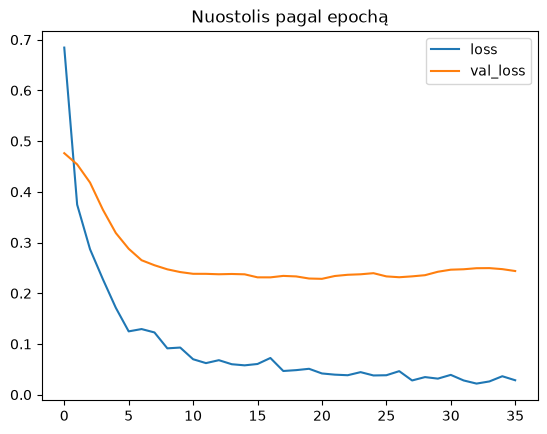

In [8]:
history = model.fit(X["train"].values, y["train"], validation_data=(X["val"].values, y["val"]),
                    epochs=200, batch_size=32, class_weight=class_weight, verbose=0,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                                restore_best_weights=True)])
print("Epochų:", len(history.history["loss"]))
pd.DataFrame(history.history)[["loss", "val_loss"]].plot(title="Nuostolis pagal epochą"); plt.show()


## 8. Slenksčio pasirinkimas validavimo aibėje

Numatytasis slenkstis 0,5 nebūtinai tinka. Kadangi svarbiausia nepraleisti aktualių dalių, validavimo aibėje parenkamas **aukščiausias slenkstis, kuriam recall ≥ 0,9**. Testo aibė šiam pasirinkimui nenaudojama. Validavimo aibėje aktualių dalių nedaug, todėl slenkstis yra apytikslis.


In [9]:
val_score = model.predict(X["val"].values, verbose=0).ravel()
candidates = np.round(np.arange(0.05, 0.96, 0.05), 2)
val_recall = [((val_score >= t) & (y["val"] == 1)).sum() / max(1, (y["val"] == 1).sum()) for t in candidates]
ok = [t for t, r in zip(candidates, val_recall) if r >= 0.9]
THRESHOLD = float(max(ok)) if ok else 0.5
print("Pasirinktas slenkstis:", THRESHOLD)


Pasirinktas slenkstis: 0.2


## 9. Galutinis įvertinimas testo aibėje


In [10]:
test_score = model.predict(X["test"].values, verbose=0).ravel()
rows = [majority_row, baseline_row,
        report("Keras NN (slenkstis 0,5)", y["test"], (test_score >= 0.5).astype(int), test_score),
        report(f"Keras NN (slenkstis {THRESHOLD})", y["test"], (test_score >= THRESHOLD).astype(int), test_score)]
results = pd.DataFrame(rows).round(3)
display(results)
nn_pred = (test_score >= THRESHOLD).astype(int)
print(classification_report(y["test"], nn_pred, target_names=["neaktualu", "aktualu"], zero_division=0))
cm = confusion_matrix(y["test"], nn_pred)
print("Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):\n", cm)
PRIVATE.joinpath("rezultatai").mkdir(exist_ok=True)
results.assign(test_fingerprint=SPLIT_FINGERPRINT).to_csv(PRIVATE / "rezultatai" / "1_3_nn.csv", index=False)


,modelis,accuracy,precision_1,recall_1,f1_1,praleista_aktualiu,klaidingai_aktualiu,PR_AUC
0,Visada 0 (dauguma),0.829,0.000,0.000,0.000,13,0,NaN
1,Bazinė raktinių žodžių taisyklė,0.789,0.444,0.923,0.600,1,15,NaN
2,"Keras NN (slenkstis 0,5)",0.803,0.333,0.154,0.211,11,4,0.467
3,Keras NN (slenkstis 0.2),0.829,0.500,0.615,0.552,5,8,0.467


              precision    recall  f1-score   support

   neaktualu       0.92      0.87      0.89        63
     aktualu       0.50      0.62      0.55        13

    accuracy                           0.83        76
   macro avg       0.71      0.74      0.72        76
weighted avg       0.85      0.83      0.84        76

Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):
 [[55  8]
 [ 5  8]]


## 10. Klaidos: kurias aktualias dalis modelis praleido?

Svarbiausia rizika — klaidingai atmestas aktualus pirkimas. Šias dalis žmogus turėtų patikrinti pagal TED nuorodą.


In [11]:
def show_errors(pred, title):
    test = raw[masks["test"]].assign(pred=pred)
    missed = test[(test.y == 1) & (test.pred == 0)]
    false_pos = test[(test.y == 0) & (test.pred == 1)]
    print(f"{title}: praleistos aktualios dalys ({len(missed)})")
    for _, r in missed.iterrows():
        print(" -", r.lot_title[:90], "|", r.source_url)
    print(f"\n{title}: klaidingai aktualiomis pažymėtos dalys ({len(false_pos)}, rodomos iki 8)")
    for _, r in false_pos.head(8).iterrows():
        print(" -", r.lot_title[:90])

show_errors(nn_pred, 'Keras NN')


Keras NN: praleistos aktualios dalys (5)
 - 1. Rinkinių komplektas skirtas genų, susijusių su solidiniais navikais ir onkohematologinė | https://ted.europa.eu/lt/notice/-/detail/778344-2026
 - 2. Rinkinių komplektas DNR ir RNR bibliotekų sekoskaitai | https://ted.europa.eu/lt/notice/-/detail/778344-2026
 - 9 pirkimo dalis Jaučio serumo albuminas (BSA) | https://ted.europa.eu/lt/notice/-/detail/663441-2025
 - 10 pirkimo dalis Fosfatinis buferis | https://ted.europa.eu/lt/notice/-/detail/663441-2025
 - Priemonės mikrobiologiniams tyrimams | https://ted.europa.eu/lt/notice/-/detail/115764-2026

Keras NN: klaidingai aktualiomis pažymėtos dalys (8, rodomos iki 8)
 - ATVIRAS KONKURSAS (SUPAPRASTNTO PIRKIMO) „INSTRUMENTAI IR PAGALBINĖS PRIEMONĖS DANTŲ ORTOP
 - 2 p.d. Petri lėkštelės, 55x14 mm
 - 4 p.d. Flakonai plastikiniai, su dujiniu filtru, audinių kultūroms, 25 cm2
 - 10 p.d. 60 ml plastikiniai buteliukai užsukamais dangteliais
 - 11 p.d. Pastero pipetės
 - 12 p.d. Filtrai švirkštui, 0,22

## 11. Išsaugoti ir iš naujo įkelti modelį

Kaip originale: išsaugotas modelis turi duoti tas pačias prognozes. Modelis saugomas `private/` aplanke, nes išmoktas iš privačių žymų.


In [12]:
path = PRIVATE / "modeliai" / "1_3_pirkimo_dalies_nn.keras"
path.parent.mkdir(exist_ok=True)
model.save(path)
reloaded = tf.keras.models.load_model(path)
same = np.allclose(reloaded.predict(X["test"].values, verbose=0).ravel(), test_score, atol=1e-6)
print("Įkeltas modelis duoda tas pačias prognozes:", same)
example = raw[masks["test"]].iloc[0]
print("Pavyzdys:", example.lot_title[:80], "→ tikimybė", round(float(test_score[0]), 3), "| žyma", example.y)


Įkeltas modelis duoda tas pačias prognozes: True
Pavyzdys: 1. Rinkinių komplektas skirtas genų, susijusių su solidiniais navikais ir onkohe → tikimybė 0.112 | žyma 1


## 12. Išvados

Skaičiai aukščiau yra šio paleidimo rezultatai. Jų interpretacija pateikta pristatymo gide (`docs/1_3_1_5_pristatymo_gidas.md`). Pagrindinės ribos: mažai skirtingų aktualių pirkimų, agento (ne žmogaus) žymos ir trumpi TED aprašymai.
